In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
##HANDLING MISSING VALUES (Data cleaning)

In [2]:
df = sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [6]:
df.isnull()


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6429,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6430,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6431,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [7]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [8]:
df.dtypes

pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                         str
payment                       str
pickup_zone                   str
dropoff_zone                  str
pickup_borough                str
dropoff_borough               str
dtype: object

In [12]:
df["payment"].mode()

0    credit card
Name: payment, dtype: str

In [17]:
 df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

In [18]:
df["payment"].isnull().sum()

np.int64(0)

In [19]:
columns = ["pickup_zone","dropoff_zone","pickup_borough","dropoff_borough"]
for col in columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [20]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [ ]:
##VISUALIZATION - matplotlib

<function matplotlib.pyplot.show(close=None, block=None)>

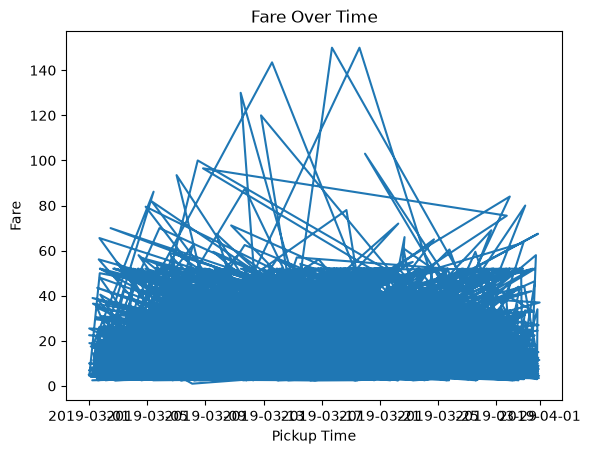

In [27]:
#line chart
plt.plot(df["pickup"],df["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.show

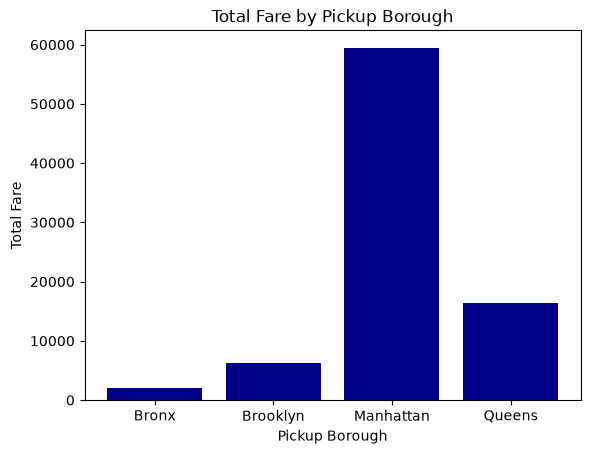

In [34]:
#bar chart
borough_fare = df.groupby('pickup_borough')['fare'].sum()
plt.bar(borough_fare.index, borough_fare.values,color="darkblue")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.show()

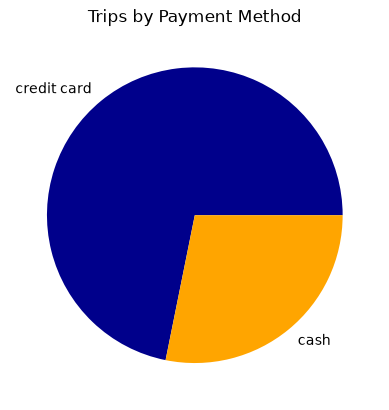

In [41]:
#pie chart
payment_count = df['payment'].value_counts()
plt.pie(payment_count, labels=payment_count.index,
       colors=["darkblue","orange"])
plt.title("Trips by Payment Method")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

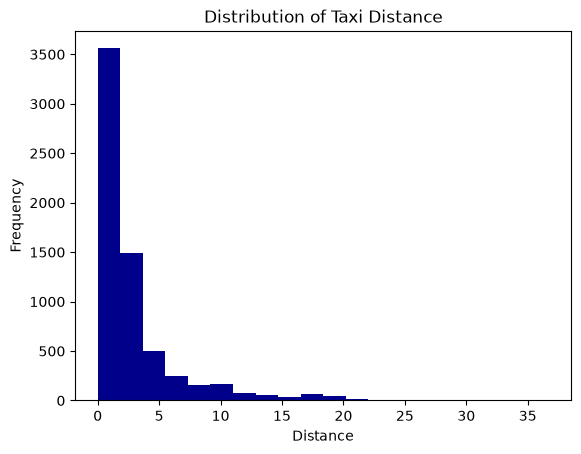

In [44]:
#histogram
plt.hist(df["distance"], bins=20, color='darkblue')
plt.title("Distribution of Taxi Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show

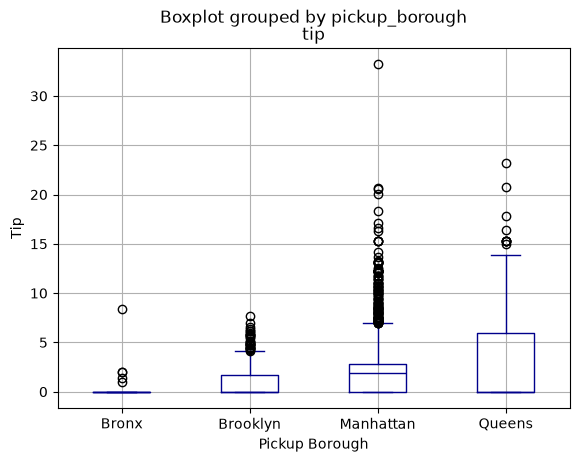

In [46]:
#boxplot
df.boxplot(column="tip", by="pickup_borough",color="darkblue")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")

plt.show()

In [ ]:
#Visualization (seaborn)

<function matplotlib.pyplot.show(close=None, block=None)>

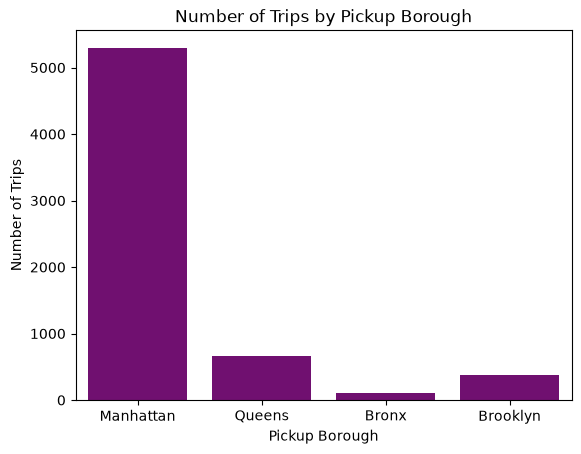

In [48]:
#countplot
sns.countplot(x="pickup_borough",data=df,color="purple")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.show

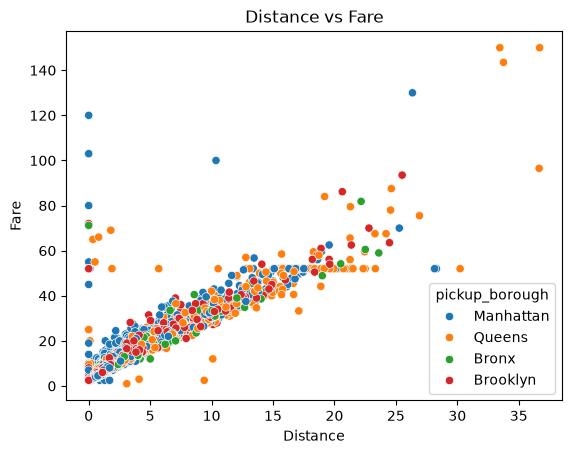

In [49]:
#scatterplot
sns.scatterplot(
    x="distance",
    y="fare",
    hue="pickup_borough",
    data=df)
plt.title("Distance vs Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.show()

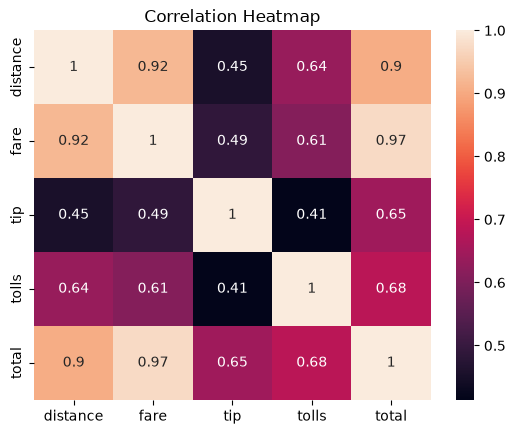

In [54]:
#heatmap
correlation = df[["distance", "fare", "tip", "tolls", "total"]].corr()
sns.heatmap(correlation, annot=True)
plt.title("Correlation Heatmap")
plt.show()

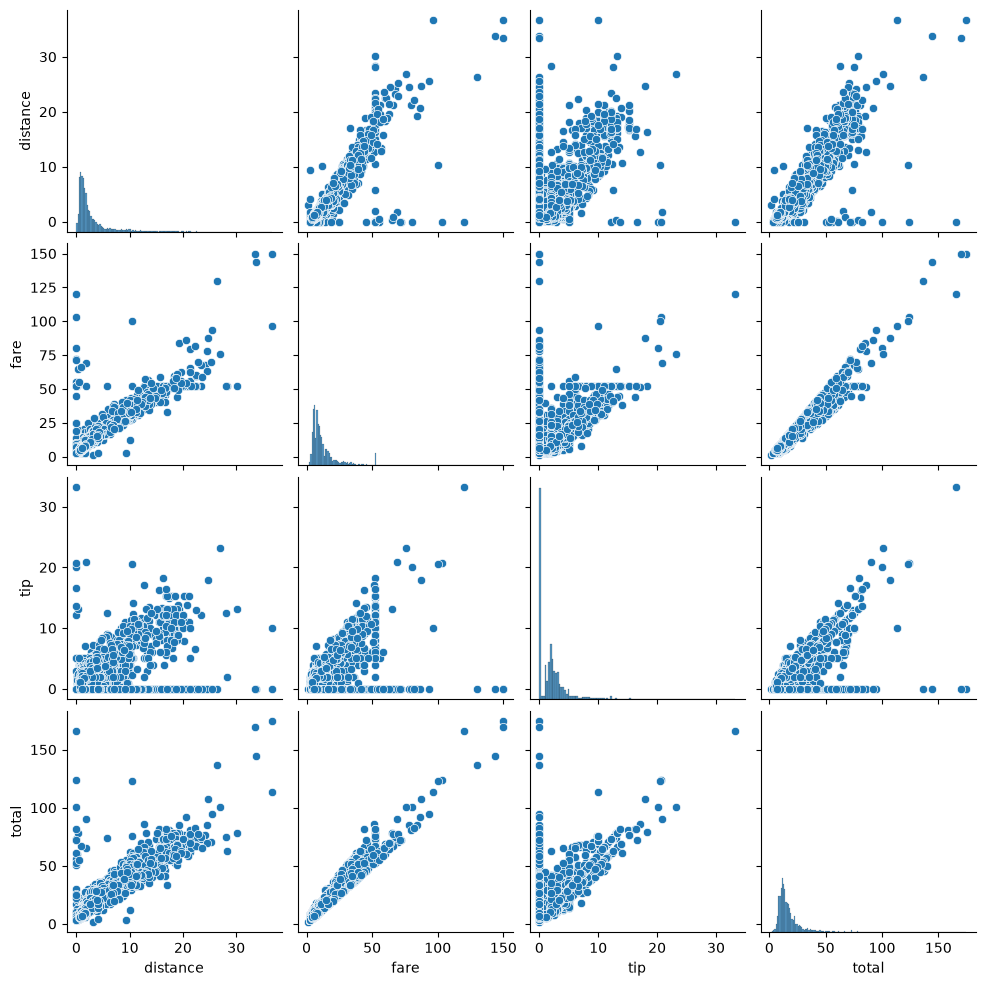

In [59]:
#pairplot
sns.pairplot(
    df[["distance", "fare", "tip", "total"]])
plt.show()

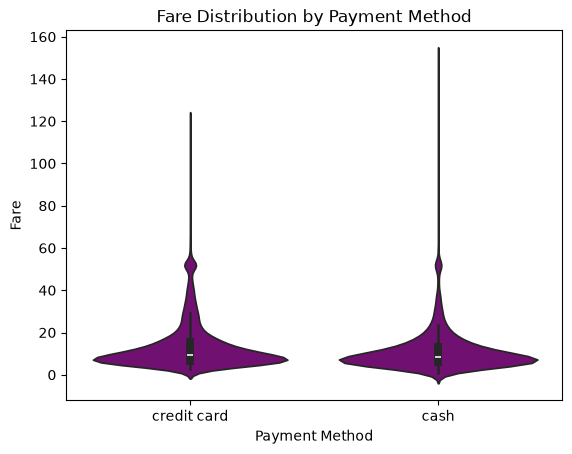

In [61]:
#violin plot
sns.violinplot(
    x="payment",
    y="fare",
    data=df,
    color="purple")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.show()